# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Starbuccks · **Tema:**Iniciação Ciêntifica e Monitoria

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/ViniciusDSB/starbucks-IA-2026-02-TP-Chatbot.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 DONE: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Starbucks | Tema: Bot Suporte Iniciação Cientifica e Monitoria


,intenção,descrição
0,editais,Posso ajudar a encontrar editais anteriores de iniciação científica e monito...
1,como_se_inscrever,Posso esclarecer dúvidas sobre os processos de inscrição e seleção para inic...
2,como_sao_relatorios,"Posso esclarecer dúvidas sobre a estrutura, o formato e os modelos de relató..."
3,requisitos_minimos,Posso esclarecer dúvidas sobre os requisitos para participar de atividades d...
4,bolsas_e_valores,Posso esclarecer dúvidas sobre bolsas de iniciação científica e monitoria re...


---
## 2. Dados

🔨 Como os dados foram construídos:

Para os dados de teste e treino, as frases humanas foram escritas pelos integrantes do grupo seguindo os requsitos a risca, tentando incoporar erros de digitação, gírias, variação de pontuação;
Par amabos, os negativos incluem fáceis e difíceis, usando palavras chaves relativas ao tema, como:

**Faceis**:
- onde fica o bloco 5?
- Onde pesquisar sobre large languagem model multimodais?

**Difíceis**:
- Quero ser monitor de disciplina no ensino médio
- Onde posso ver o edital de seleção do mestrado

As frases de llm foram feitas geradas por intenção, para facilitar organização e contagem, e fornecendo alguns documentos de exemplo, além da seção de intenções do grupo.yaml. Vários prompts foram usados e varias saídas descartadas pela eliminação de frases repetidas.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
bolsas_e_valores,10,40,50
chitchat,20,79,99
como_sao_relatorios,10,40,50
como_se_inscrever,11,40,51
editais,10,40,50
fora_dominio,30,138,168
requisitos_minimos,10,40,50
total,101,417,518


origem,humano,total
intencao,,
bolsas_e_valores,15,15
chitchat,30,30
como_sao_relatorios,16,16
como_se_inscrever,15,15
editais,16,16
fora_dominio,40,40
requisitos_minimos,15,15
total,147,147


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [5]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 Não usaos esse gerador de frases
Seçao:  análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [ ]:
# 🔨 TODO

---
## 3. Representações de texto

🔨 Foram escolhidas representadoes TF-IDF com palavras e caracteres para comparação.

In [6]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 Mantidos classificadores por rede neural, regressão logística e árvore de decisão.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    # 🔨 TODO: acrescente outros
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.926,0.041,0.938,1.000
1,TF-IDF caracteres,Rede neural (MLP),0.923,0.039,0.932,1.000
2,TF-IDF palavras,Rede neural (MLP),0.910,0.022,0.915,1.000
3,TF-IDF palavras,Regressão logística,0.897,0.016,0.911,0.998
4,TF-IDF palavras,Árvore de decisão,0.822,0.024,0.838,1.000
5,TF-IDF caracteres,Árvore de decisão,0.751,0.046,0.774,1.000


- ampliamos os valores de `C`, pois o melhor resultado anterior estava no limite superior da grade 100. Queremos verificar se 1000 melhora ainda mais.
- testamos dois valores de `ngram_range`, para verificar se sequências de até quatro ou cinco caracteres produzem melhores resultados.

In [8]:
busca_escopo = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()),
        ("classificador", LogisticRegression(max_iter=2000))
    ]),
    param_grid={
        "classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
        "vetorizador__ngram_range": [(2, 4), (2, 5)]
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_

No contexto de iniciação científica e monitoria, informações incorretas sobre requisitos, prazos de inscrição, bolsas ou procedimentos podem prejudicar diretamente os estudantes. Portanto o falso "pertence ao dominio" é mais grave.

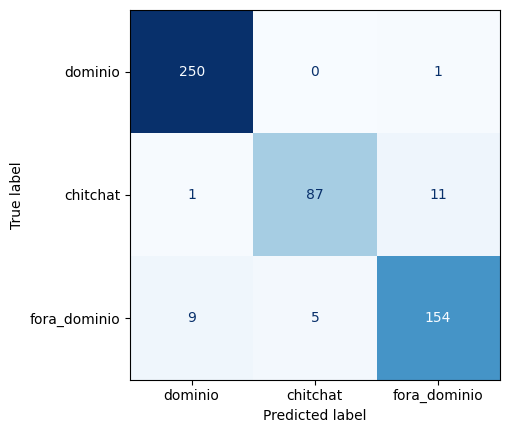

,texto,escopo,previsto,origem
7,"Salve, inteligência artificial!",chitchat,fora_dominio,llm
11,Quanto tempo!,chitchat,fora_dominio,llm
18,"Oi, meu amigo virtual.",chitchat,fora_dominio,llm
24,Gratidão!,chitchat,fora_dominio,llm
31,"Tchau, até a próxima.",chitchat,fora_dominio,llm
39,Até qualquer hora.,chitchat,fora_dominio,llm
43,Na correria de sempre.,chitchat,fora_dominio,llm
46,Não posso reclamar.,chitchat,fora_dominio,llm
55,Me faz rir um pouco.,chitchat,fora_dominio,llm
60,Preciso de uma distração.,chitchat,dominio,llm


In [9]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 Mesma configuração, treinando **apenas** com as mensagens do domínio para classificalçao de intenções.

O classificador escolhido foi também regressor linear com TF-IDF em caracteres.

In [10]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.959,0.034,0.960,1.0
1,TF-IDF palavras,Regressão logística,0.940,0.024,0.940,1.0
2,TF-IDF caracteres,Rede neural (MLP),0.938,0.036,0.940,1.0
3,TF-IDF palavras,Rede neural (MLP),0.896,0.024,0.897,1.0
4,TF-IDF caracteres,Árvore de decisão,0.861,0.041,0.860,1.0
5,TF-IDF palavras,Árvore de decisão,0.838,0.045,0.837,1.0


In [11]:
treino_dominio = treino[treino["escopo"] == "dominio"]

busca_tema = GridSearchCV(
    Pipeline([
        ("vetorizador", tfidf_caracteres()),
        ("classificador", LogisticRegression(max_iter=2000))
    ]),
    param_grid={
        "classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
        "vetorizador__ngram_range": [(2, 4), (2, 5)]
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

busca_tema.fit(
    treino_dominio["texto"],
    treino_dominio["intencao"]
)

clf_tema = busca_tema.best_estimator_

print(busca_tema.best_params_)
print(round(busca_tema.best_score_, 3))

{'classificador__C': 1000, 'vetorizador__ngram_range': (2, 4)}
0.967


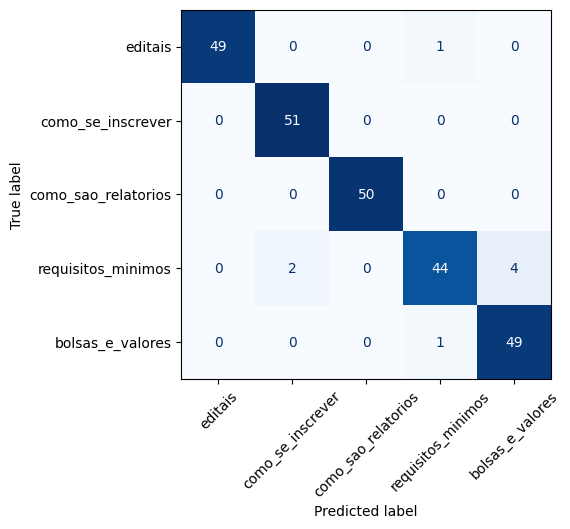

                     precision    recall  f1-score   support

   bolsas_e_valores       0.92      0.98      0.95        50
como_sao_relatorios       1.00      1.00      1.00        50
  como_se_inscrever       0.96      1.00      0.98        51
            editais       1.00      0.98      0.99        50
 requisitos_minimos       0.96      0.88      0.92        50

           accuracy                           0.97       251
          macro avg       0.97      0.97      0.97       251
       weighted avg       0.97      0.97      0.97       251



In [12]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

- Obtendo probabilidades da validação cruzada

In [13]:
proba = cross_val_predict(
    clf_tema,
    treino_dom["texto"],
    treino_dom["intencao"],
    cv=cv,
    method="predict_proba"
)

classes = clf_tema.classes_

confianca = proba.max(axis=1)
previsto = classes[proba.argmax(axis=1)]

real = treino_dom["intencao"].to_numpy()
acertou = previsto == real

Comparando diferentes limiares de confiança
Interpretação das colunas:
- respondidas: quantidade de mensagens que receberiam uma resposta direta.
- esclarecimentos: mensagens nas quais o chatbot pediria esclarecimento.
- cobertura: percentual de mensagens respondidas diretamente.
- acurácia nas respondidas: percentual de acertos entre as mensagens que receberam resposta direta.
- erros diretos: respostas incorretas que o chatbot ainda daria.
- erros evitados: previsões incorretas que seriam interceptadas pelo limiar.
- acertos que viraram perguntas: previsões que estavam corretas, mas seriam encaminhadas para esclarecimento.

In [14]:
limiares = [0.3, 0.4, 0.5, 0.6]

resultados = []

for limiar in limiares:
    responde = confianca >= limiar

    respondidas = responde.sum()
    esclarecimentos = (~responde).sum()

    acertos_diretos = (responde & acertou).sum()
    erros_diretos = (responde & ~acertou).sum()

    erros_evitados = (~responde & ~acertou).sum()
    acertos_viraram_pergunta = (~responde & acertou).sum()

    resultados.append({
        "limiar": limiar,
        "respondidas": respondidas,
        "esclarecimentos": esclarecimentos,
        "cobertura (%)": 100 * respondidas / len(real),
        "acurácia nas respondidas (%)":
            100 * acertos_diretos / respondidas if respondidas else 0,
        "erros diretos": erros_diretos,
        "erros evitados": erros_evitados,
        "acertos que viraram perguntas": acertos_viraram_pergunta
    })

tab_limiares = pd.DataFrame(resultados)
tab_limiares.round(2)

,limiar,respondidas,esclarecimentos,cobertura (%),acurácia nas respondidas (%),erros diretos,erros evitados,acertos que viraram perguntas
0,0.3,251,0,100.00,96.81,8,0,0
1,0.4,251,0,100.00,96.81,8,0,0
2,0.5,248,3,98.80,96.77,8,0,3
3,0.6,245,6,97.61,97.14,7,1,5


Escolhemos o limiar de confiança 0.5 por oferecer um equilíbrio adequado entre a quantidade de mensagens respondidas e a prevenção de classificações incorretas.

---
## 7. Salvar os modelos finais

In [ ]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "Onde encontro editais?", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py